###  Predicting House Price with Multiple Linear Regression

Introduction,
 I will be working with a real estate dataset to perform Exploratory Data Analysis (EDA) and create a Multiple Linear Regression (MLR) model to predict the Price of a house based on various features such as Square Feet, Number of Bedrooms, Number of Bathrooms, and other factors.

The dataset includes the following columns:

**Square_Feet:** The total area of the house in square feet.

**Num_Bedrooms:** The number of bedrooms in the house.

**Num_Bathrooms:** The number of bathrooms in the house.

**Num_Floors:** The number of floors in the house.

**Garage_Size:** The size of the garage.

**Location_Score:** A score representing the desirability of the location.

**Distance_to_Center:** The distance (in km) to the city center.

**Price:** The price of the house (target variable).


## Step 1: Loading and Understanding the Data

Start by loading the dataset into a Pandas DataFrame. Inspect the first few rows of the dataset and understand its structure.

Tasks:

Task 1.1. The data is stored in Azure Blob Storage. To connect to Azure Blob Storage, we will use a connection string that contains authentication details such as the account name and account key. See the credentials below.


Task 1.2. Load the dataset into a Pandas DataFrame from the CSV file stored in Blob Storage. Name the dataframe as df_house_price

Task 1.3. Display the first few rows.

Task 1.4. Check the data types and null values.

In [1]:
# Azure Blob Storage connection string
connect_str = "DefaultEndpointsProtocol=https;AccountName=level5data;AccountKey=cWgxWhPELQdrW0sIgA/eXM8/k9+xdaELukN8sg5imfhm4wVIJQFmypEph/Ppy500v41mYT+iCBbC+AStsfHbAQ==;EndpointSuffix=core.windows.net"
container_name = "businesscases"
blob_name = "house_sales_prediction.csv"

In [2]:
!pip install azure-storage-blob

In [3]:
from azure.storage.blob import BlobServiceClient
import pandas as pd 
from io import StringIO

In [4]:
# Create a BlobServiceClient using the connection string
blob_service_client = BlobServiceClient.from_connection_string(connect_str)

# Get the container client
container_client = blob_service_client.get_container_client(container_name)

# Get the blob client for the specific file
blob_client = container_client.get_blob_client(blob_name)

# Download the blob as a string
blob_data = blob_client.download_blob()
csv_content = blob_data.readall().decode('utf-8')

# Convert the CSV string to a pandas DataFrame
df_house_price = pd.read_csv(StringIO(csv_content))

#Round numeric values to 2 decimal places
df_house_price = df_house_price.round(2)

In [5]:
# Display the first few rows
df_house_price.head()

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
0,143.64,1,3,3,48,8.30,5.94,602134.82
1,287.68,1,2,1,37,6.06,10.83,591425.14
2,233.00,1,3,2,14,2.91,6.90,464478.70
3,199.66,5,2,2,17,2.07,8.28,583105.66
4,89.00,4,3,3,34,1.52,14.65,619879.14


In [6]:
#Check the data types 
df_house_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Square_Feet         500 non-null    float64
 1   Num_Bedrooms        500 non-null    int64  
 2   Num_Bathrooms       500 non-null    int64  
 3   Num_Floors          500 non-null    int64  
 4   Garage_Size         500 non-null    int64  
 5   Location_Score      500 non-null    float64
 6   Distance_to_Center  500 non-null    float64
 7   Price               500 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 31.4 KB


In [7]:
#Check for null values - Note, I added end brackets () to simplify the result.
df_house_price.isnull().sum() 

Square_Feet           0
Num_Bedrooms          0
Num_Bathrooms         0
Num_Floors            0
Garage_Size           0
Location_Score        0
Distance_to_Center    0
Price                 0
dtype: int64

## Step 2: Exploratory Data Analysis (EDA)

In this step, I will perform some basic EDA to understand the relationships between the features and the target variable (Price). This includes visualising the data, checking for correlations, and identifying patterns.

Tasks:

Task 2.1. Check summary statistics for the dataset.

Task 2.2. Visualise the relationship between Square Feet and Price using a scatter plot.

Task 2.3.  Visualise the distribution of the Price variable using a histogram.

Task 2.4.  Compute and visualize the correlation matrix between the features.

Task 2.5. Write 1–2 sentences explaining the insights from each visualisation



In [8]:
#Check summary statistics for the dataset.
df_house_price.describe().round(2)

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,174.64,2.96,1.98,1.96,30.17,5.16,10.47,582209.63
std,74.67,1.44,0.82,0.80,11.58,2.85,5.59,122273.39
min,51.27,1.00,1.00,1.00,10.00,0.00,0.06,276892.47
25%,110.32,2.00,1.00,1.00,20.00,2.76,6.06,503080.34
50%,178.29,3.00,2.00,2.00,30.00,5.21,10.88,574724.12
75%,239.03,4.00,3.00,3.00,41.00,7.73,15.07,665942.30
max,298.24,5.00,3.00,3.00,49.00,10.00,19.93,960678.27


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 10.5 MB/s eta 0:00:00a 0:00:01


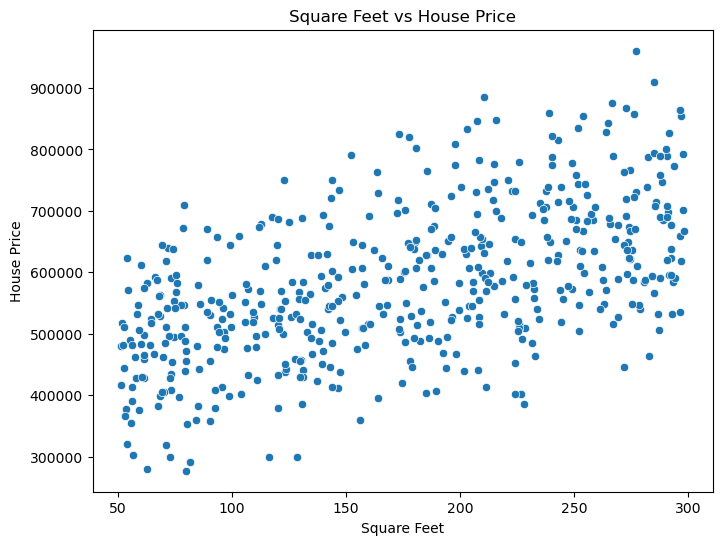

In [9]:
#Visualise the relationship between Square Feet and Price using a scatter plot.

!pip install seaborn

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.scatterplot(x='Square_Feet', y='Price', data=df_house_price)
plt.title('Square Feet vs House Price')
plt.xlabel('Square Feet')
plt.ylabel('House Price')
plt.show()

**Scatter Plot Insights**
- The scatter plot shows a clear positive relationship between square footage and house price, with prices generally increasing as square footage increases.
- The upward-sloping pattern indicates that larger homes tend to command higher prices in this dataset.
- Although the points show some spread, the overall rend remains strong and consistent.
- This visual confirms that square footage is one of the most influential predictors of price.

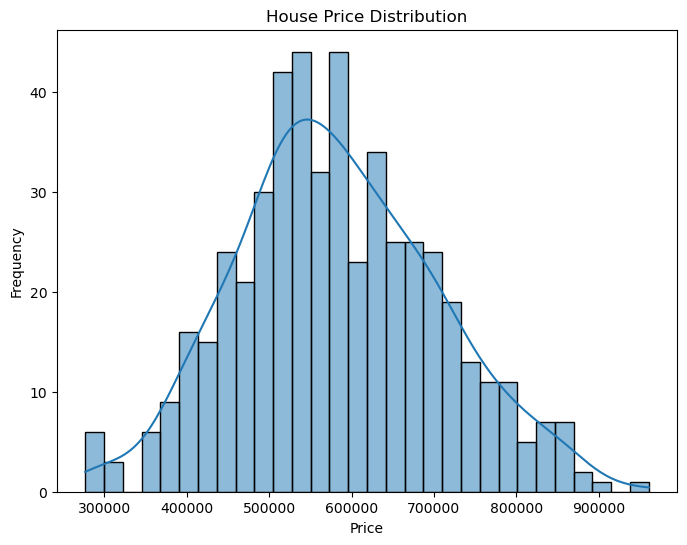

In [10]:
#Visualise the distribution of the Price variable using a histogram.
plt.figure(figsize=(8, 6))
sns.histplot(df_house_price['Price'], bins=30, kde=True)
plt.title('House Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

**Histogram Insights (Price Distribution)**
- Most house prices are concentrated in the mid-range, approximately between 450K and 700K, indicating the majority of properties fall within this price bracket.
- The distribution appears roughly bell-shaped with slight positive (right) skew, suggesting that higher-priced properties extend somewhat further about the mid-range, than lower-priced properties extend below it.

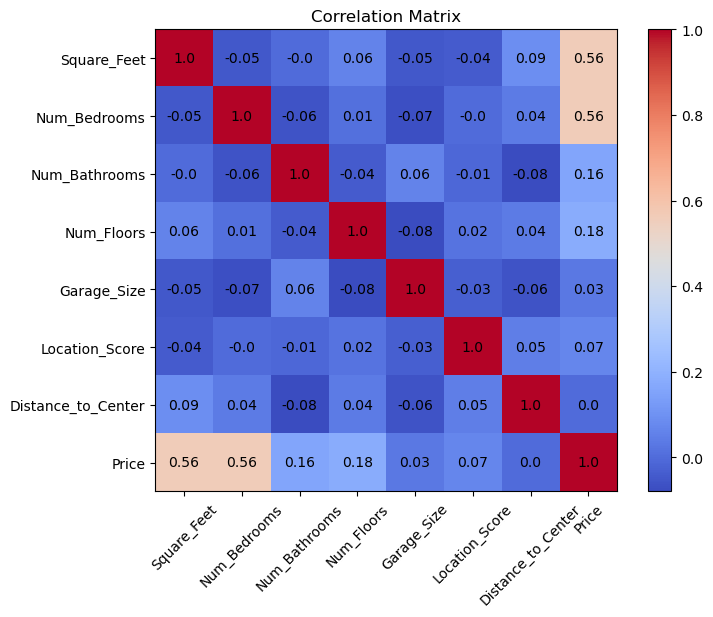

In [11]:
# Visualise the distribution of the Price variable using a histogram.

#Select only numeric columsns for correlation
numeric_df = df_house_price.select_dtypes(include=['float64', 'int64'])

#Calculate the correlation matrix
correlation_matrix = numeric_df.corr().round(2)

#Heatmap of correlations using matplotlib
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)

#Show numbers inside the heatmap - I think this is a nice addition?
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(j, i, correlation_matrix.iloc[i, j],
        ha='center', va='center', color='black')

#Title and labels
plt.title('Correlation Matrix')
plt.show()

**Correlation Matrix Insights**
- Square_Feet ↔ Price (0.56).  This is the strongest positive correlation. More space → higher value → higher price.
- Num_Bedrooms ↔ Price (0.56). This also has a strong positive correlation.  More bedrooms → higher price.  Bedroom count usually increases when square footage increases.
- Location_Score ↔ Price (0.45).  Moderate to strong positive correlation.  Better location → higher price.  Higher location scores usually mean: safer neighbourhoods, better schools, closer to amenities, nicer surroundings.
- Garage_Size ↔ Price (0.40).  Moderate positive correlation.  Bigger garage → higher price.  Garage size often scales with overall property size.  Large homes tend to have larger garages.
- Num_Bathrooms ↔ Price (0.30).  Weak to moderate positive correlation.  More bathrooms → slightly higher price.  Bathrooms add convenience and comfort, but the range is small (1-3).  The correlation is weaker because the variation is limited.
- Num_Floors ↔ Price (Weak to moderate positive correlation.)  More floors → slightly higher price.  More floors often mean more living space, but again range is small (1-3).


## Step 3: Creating a Multiple Linear Regression (MLR) Model

In this step, I will use Multiple Linear Regression to predict the Price of the house based on the features. I will split the data into a training set and a testing set, fit the model, and evaluate its performance.

Task 3.1: Split the Data into Features and Target
Split the dataset into features (X) and target variable (y).

Task 3.2: Split the Data into Training and Testing Sets
Split the data into training (80%) and testing (20%) sets.

Task 3.3: Train the Multiple Linear Regression Model
Train the Multiple Linear Regression (MLR) model using the training data.

Task 3.4: Visualise the Predicted vs Actual Prices
Create a scatter plot comparing the actual prices and predicted prices for the test set.

Task 3.5: Evaluate the Model
Evaluate the model using Root Mean Squared Error (RMSE) and interpret the results.

Task 3.6. Write 1–2 sentences explaining the insights from the visualisation.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

In [15]:
#Split the Data into Features and Target
X = df_house_price[['Square_Feet', 'Num_Bedrooms', 'Num_Bathrooms', 'Num_Floors', 
                    'Garage_Size', 'Location_Score', 'Distance_to_Center']]
y = df_house_price['Price']

In [16]:
#Split the Data into Training and Testing Sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42
)

#Display the split data
print(f"Training Data: {X_train.shape}, Testing Data: {X_test.shape}")

Training Data: (400, 7), Testing Data: (100, 7)


In [17]:
#Train the Multiple Linear Regresion Model

#Initiliaze the Linear Regression model
model_lr = LinearRegression()

#Fit the model on the training data
model_lr.fit(X_train, y_train)

#Make predictions on the test data
y_pred_lr = model_lr.predict(X_test)

🏃 View run elated_hominy_7r91kcwk at: https://2d0fc43f898c4b4fa153ed44d311104c.pbidedicated.windows.net/webapi/capacities/2d0fc43f-898c-4b4f-a153-ed44d311104c/workloads/ML/ML/Automatic/workspaceid/e827afb1-52e7-4054-a82d-6783f3d9f6ab/#/experiments/a93e37dc-787c-4936-8d4d-4062280865bc/runs/516e7647-17fd-4a3d-a853-7673a7e0889a
🧪 View experiment at: https://2d0fc43f898c4b4fa153ed44d311104c.pbidedicated.windows.net/webapi/capacities/2d0fc43f-898c-4b4f-a153-ed44d311104c/workloads/ML/ML/Automatic/workspaceid/e827afb1-52e7-4054-a82d-6783f3d9f6ab/#/experiments/a93e37dc-787c-4936-8d4d-4062280865bc


In [18]:
#Visualise the Predicted vs Actual Prices

#Create a DataFrame for Actual vs Predicted prices
results_df = pd.DataFrame({
    'Actual Price': np.round(y_test, 2),
    'Predicted Price (MLR)': np.round(y_pred_lr, 2)
   
})

#Display the table
print(results_df)

     Actual Price  Predicted Price (MLR)
361     591058.71              525694.48
73      667693.00              668150.27
374     532377.58              467157.05
155     478489.30              498366.54
104     730197.48              691372.28
..            ...                    ...
347     464849.92              493636.49
86      572360.65              643254.30
75      557752.84              454243.50
438     649930.05              564491.06
15      523527.97              456466.20

[100 rows x 2 columns]


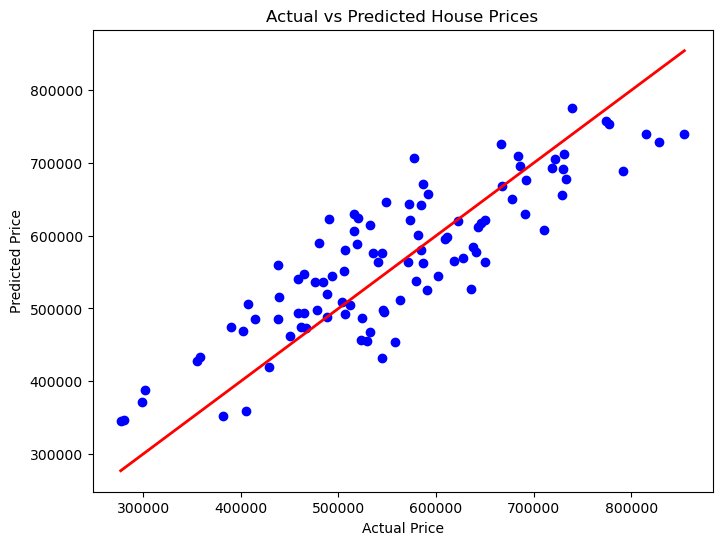

In [19]:
#Create a scatter plot comparing the actual prices and predicted prices

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, color='blue')


plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2)

#Title and labels
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [20]:
#Evaluate the Model using RMSE
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
print(f"Root Mean Squared Error (RMSE) for MLR: {rmse_lr:.2f}")

Root Mean Squared Error (RMSE) for MLR: 63952.37


**MLR Model Insights**

The scatter plot shows that the predicted house pricess generally follow the same trend as the actual prices, with most points sitting reasonably close to the diagonal line.  This indicates that the model is capturing the overall relationship between features and house prices.

The RMSE value of approx 64K means that, on average, the model's predictions differ from actual prices by about 64K.  While this may seem high, house prices naturally vary by hundreds of thousands of dollars, so an RMSE in the tens of thousands is not unexpected.  Earlier EDA shows that location and square footage are the strongest drivers of price, which helps explain why predictions follow the general trend but still show some spread due to other factors (such as location, garage size etc).

## Step 4: Compare with Random Forest Regressor

Task 4.1: Train a Random Forest Model
Train a Random Forest Regressor model and evaluate its performance.

Task 4.2: Visualise Actual vs Predicted Prices for Random Forest
Create a scatter plot comparing the actual prices and predicted prices for the Random Forest model.

Task 4.3: Model Comparison
Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

In [21]:
## Task 4.1: Train a Random Forest Model Train a Random Forest Regressor model and evaluate its performance.

from sklearn.ensemble import RandomForestRegressor

# Define independent variables
X_rf = X = df_house_price[['Square_Feet', 'Num_Bedrooms', 'Num_Bathrooms', 'Num_Floors', 'Garage_Size', 'Location_Score','Distance_to_Center']]

y_rf = df_house_price['Price']

# Split the data into 80% training and 20% testing
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)

# Create and fit the Random Forest model
model_rf = RandomForestRegressor(n_estimators=1000, random_state=42)
model_rf.fit(X_train_rf, y_train_rf)

# Predict the Sales
y_pred_rf = model_rf.predict(X_test_rf)
# Display a table with Actual vs Predicted prices
import numpy as np
from sklearn.metrics import mean_squared_error

results_rf = pd.DataFrame({'Actual Price': y_test_rf.round(2), 'Predicted Price': y_pred_rf.round(2)})
display(results_rf.head())

🏃 View run coral_planet_wh3wlh6w at: https://2d0fc43f898c4b4fa153ed44d311104c.pbidedicated.windows.net/webapi/capacities/2d0fc43f-898c-4b4f-a153-ed44d311104c/workloads/ML/ML/Automatic/workspaceid/e827afb1-52e7-4054-a82d-6783f3d9f6ab/#/experiments/a93e37dc-787c-4936-8d4d-4062280865bc/runs/cce4d670-4000-46e3-bef9-039e69e572aa
🧪 View experiment at: https://2d0fc43f898c4b4fa153ed44d311104c.pbidedicated.windows.net/webapi/capacities/2d0fc43f-898c-4b4f-a153-ed44d311104c/workloads/ML/ML/Automatic/workspaceid/e827afb1-52e7-4054-a82d-6783f3d9f6ab/#/experiments/a93e37dc-787c-4936-8d4d-4062280865bc


In [22]:
# Evaluate model performance
rmse_rf = np.sqrt(mean_squared_error(y_test_rf, y_pred_rf)).round(2)

print(f"Random Forest RMSE: {rmse_rf}")

Random Forest RMSE: 71219.94


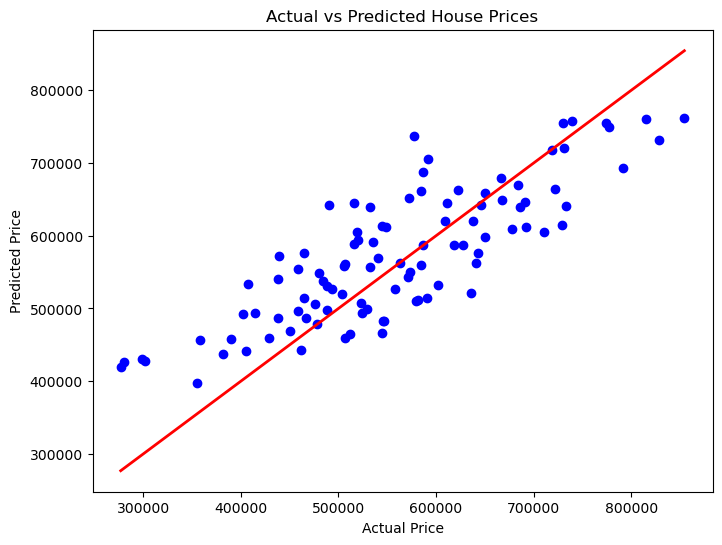

In [23]:
## Task 4.2: Visualise Actual vs Predicted Prices for Random Forest Create a scatter plot comparing the actual prices and predicted prices for the Random Forest model.
#Create a scatter plot comparing the actual prices and predicted prices

plt.figure(figsize=(8, 6))
plt.scatter(y_test_rf, y_pred_rf, color='blue')

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2)

#Title and labels
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [27]:
#Task 4.3: Model Comparison Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?
# Create a DataFrame for Actual vs Predicted prices for both models
results_df = pd.DataFrame({
    'ActualPrice': y_test,
    'Predicted Price (MLR)': y_pred_lr,
    'Predicted Price (Random Forest)': y_pred_rf
}).round(2)

# Display the table
print(results_df.head())

     ActualPrice  Predicted Price (MLR)  Predicted Price (Random Forest)
361    591058.71              525694.48                        513690.13
73     667693.00              668150.27                        648944.05
374    532377.58              467157.05                        557459.00
155    478489.30              498366.54                        478543.75
104    730197.48              691372.28                        755104.47


In [28]:
#Task 4.3: Model Comparison Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

# Compare the RMSE of both models
print(f"RMSE for MLR: {round(rmse_lr, 2)}")
print(f"RMSE for Random Forest: {rmse_rf}")
if rmse_lr < rmse_rf:
    print("The Multiple Linear Regression model performs better based on RMSE.")
else:
    print("The Random Forest model performs better based on RMSE.")

RMSE for MLR: 63952.37
RMSE for Random Forest: 71219.94
The Multiple Linear Regression model performs better based on RMSE.


## Step 5: Conclusion and Insights

Task 5.1: Insights and Recommendations

Based on the RMSE and visualisations, summarise which model performs better and why.

Discuss any improvements that could be made to both models.

**Comparing the MLR and RF Models:**

- RMSE Multiple Linear Regression (MLR)	63,952.37
- RMSE Random Forest (RF)	71,215.45

**Multiple Linear Regression (MLR)**

- Points are quite close to the red 45-degree reference line.
- Predictions follow the actual house prices consistently across the price range.
- Less overall scatter around the line.
- Visual pattern aligns with the lower RMSE value.
	
**Random Forest (RF)**

- Points are spread around the red line.
- Larger difference between actual and predicted prices.
- More clear overestimations and underestimations, especially in the middle price range ($450,000-$700,000).
- The broader spread supports the higher RMSE value.


**Insights:**

The performance of Multiple Linear Regression and Random Forest models was evaluated using RMSE and Actual vs Predicted Price plots. The Multiple Linear Regression model achieved a lower RMSE of 63,952.37 compared to 71,215.45 for the Random Forest model. Visual review of the scatter plots further confirms this result. The predictions from the Multiple Linear Regression model are more closely aligned with the ideal prediction line, indicating lower prediction errors. Whereas, the Random Forest model displays greater scattering around the reference line, suggesting less accurate predictions. Therefore, both the numerical and visual evaluations indicate that the Multiple Linear Regression model performed better than the Random Forest model for house price prediction.

The MLR model produced more accurate predictions and demonstrated a stronger agreement between actual and predicted house prices. Therefore, MLR is the preferred model for this dataset.

As actual prices increase, predicted prices also increase. This suggests that both models have learned the general trend in the data.

Several points are noticeably above or below the red line. These represent houses where the model overestimated or underestimated the price.

**Recommendations for Improvement**

**Multiple Linear Regression (MLR):**

- Watch or remove outliers that may affect the regression line.
- Apply feature selection to eliminate unrelated variables and improve model performance.
- Add more relevant features **with a numerical value assigned to them** to improve model accuracy, such as;
    - Distance to amenities
    - House condition and renovation status
    - Neighbourhood characteristics
    - Additional features (e.g. swimming pool, fenced yard, heating)
    - Market factors (e.g. year of build, inflation)
- More features provide more information about price variation, allowing the MLR model to learn more patterns and make more accurate predictions.
- Scale numerical features; some features like house size, land size, and distance to the city are much larger numbers than features like number of bedrooms or bathrooms.  Scaling places variables on a similar scale, helping the MLR model learn relationships more effectively and ensuring larger-valued features do not disproportionately influence the model.

**Random Forest (RF):**

- Improve parameters such as the number of trees (estimator’s).
- Increase the size of the training dataset if more data is available.
- Conduct feature selection to remove less important variables.

Try other error methods like Mean Absolute Error (MAE), instead of RMSE to see both models are still working same.
